In [8]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Sales_transactions_2022_2025.csv")

# Outputs the first 5 in the dataset
df.head()

,Transaction_ID,Order_ID,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Segment,Order_Date,Order_Time,Sales_Channel,...,Order_Status,Shipping_Method,Delivery_Days,Return_Flag,Return_Reason,Sales_Representative,Promotion_Code,Customer_Rating,Inventory_Level,Order_Year
0,T02016694,O0116694,C01482,Sophia Smith,28.0,Male,Consumer,2022-10-06,11:30:55,Online,...,Completed,Standard,4.0,No,NaN,James Anderson,SAVE10,4.0,81.0,2022
1,T02016374,O0108187,C01591,Hannah King,46.0,Female,Consumer,2024-06-03,17:06:29,Online,...,Completed,Standard,6.0,No,NaN,Ella Lewis,NaN,5.0,123.0,2024
2,T02004099,O0104099,C04140,Emma Wilson,42.0,Male,Consumer,2024-12-19,08:22:11,Online,...,Shipped,Standard,4.0,No,NaN,Liam Davis,NaN,4.0,93.0,2024
3,T02010280,O0110280,C03663,Daniel Clark,18.0,Male,Corporate,2025-10-05,14:32:43,B2B Portal,...,Completed,Next Day,2.0,No,NaN,Grace Harris,HOLIDAY20,NaN,59.0,2025
4,T02012685,O0112685,C02749,Sophia Smith,37.0,Male,Returning Customer,2022-09-13,14:55:16,B2B Portal,...,Completed,Express,2.0,No,NaN,Sophia Brown,NaN,2.0,56.0,2022


In [9]:
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18045 entries, 0 to 18044
Data columns (total 36 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Transaction_ID        18045 non-null  str    
 1   Order_ID              18045 non-null  str    
 2   Customer_ID           18045 non-null  str    
 3   Customer_Name         17937 non-null  str    
 4   Customer_Age          17827 non-null  float64
 5   Customer_Gender       17883 non-null  str    
 6   Customer_Segment      18045 non-null  str    
 7   Order_Date            18045 non-null  str    
 8   Order_Time            18045 non-null  str    
 9   Sales_Channel         18045 non-null  str    
 10  Store_ID              18045 non-null  str    
 11  Store_Name            18045 non-null  str    
 12  Country               18045 non-null  str    
 13  Region                18045 non-null  str    
 14  City                  18045 non-null  str    
 15  Product_ID            18045 no

In [13]:
# prints info about the dataset
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18045 entries, 0 to 18044
Data columns (total 36 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Transaction_ID        18045 non-null  str    
 1   Order_ID              18045 non-null  str    
 2   Customer_ID           18045 non-null  str    
 3   Customer_Name         17937 non-null  str    
 4   Customer_Age          17827 non-null  float64
 5   Customer_Gender       17883 non-null  str    
 6   Customer_Segment      18045 non-null  str    
 7   Order_Date            18045 non-null  str    
 8   Order_Time            18045 non-null  str    
 9   Sales_Channel         18045 non-null  str    
 10  Store_ID              18045 non-null  str    
 11  Store_Name            18045 non-null  str    
 12  Country               18045 non-null  str    
 13  Region                18045 non-null  str    
 14  City                  18045 non-null  str    
 15  Product_ID            18045 no

In [17]:
# Checks column names and data quality
df.columns.tolist()
df.isna().sum()
print("Duplicates: ", df.duplicated().sum())
df.describe()

Duplicates:  45


,Customer_Age,Quantity,Unit_Price,Discount_Percentage,Sales_Amount,Cost_Amount,Profit,Delivery_Days,Customer_Rating,Inventory_Level,Order_Year
count,17827.000000,18045.000000,18045.000000,18045.000000,18045.000000,18045.000000,18045.000000,17883.000000,14610.000000,17847.000000,18045.000000
mean,38.916924,2.127127,232.685633,6.256858,457.309027,366.001156,91.404131,2.262204,3.985969,70.257914,2023.566417
std,10.727357,1.786212,294.208022,6.881178,856.597181,705.866738,167.827883,2.321656,1.008422,22.042609,1.118744
min,4.000000,-3.000000,21.390000,0.000000,16.680000,12.170000,-299.310000,0.000000,1.000000,0.000000,2022.000000
25%,32.000000,1.000000,53.380000,0.000000,78.530000,56.120000,19.480000,0.000000,4.000000,55.000000,2023.000000
50%,39.000000,2.000000,99.870000,5.000000,168.810000,122.300000,40.190000,1.000000,4.000000,70.000000,2024.000000
75%,46.000000,3.000000,285.580000,10.000000,472.450000,376.020000,93.270000,4.000000,5.000000,85.000000,2025.000000
max,112.000000,11.000000,1425.090000,110.000000,14303.070000,10791.000000,3512.080000,10.000000,5.000000,157.000000,2025.000000


In [24]:
# cleans data
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df = df.drop_duplicates()
df["Revenue"] = df["Quantity"] * df["Unit_Price"]
df.head()

,Transaction_ID,Order_ID,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Segment,Order_Date,Order_Time,Sales_Channel,...,Delivery_Days,Return_Flag,Return_Reason,Sales_Representative,Promotion_Code,Customer_Rating,Inventory_Level,Order_Year,Revenue,Month
0,T02016694,O0116694,C01482,Sophia Smith,28.0,Male,Consumer,2022-10-06,11:30:55,Online,...,4.0,No,NaN,James Anderson,SAVE10,4.0,81.0,2022,170.58,2022-10
1,T02016374,O0108187,C01591,Hannah King,46.0,Female,Consumer,2024-06-03,17:06:29,Online,...,6.0,No,NaN,Ella Lewis,NaN,5.0,123.0,2024,353.10,2024-06
2,T02004099,O0104099,C04140,Emma Wilson,42.0,Male,Consumer,2024-12-19,08:22:11,Online,...,4.0,No,NaN,Liam Davis,NaN,4.0,93.0,2024,87.84,2024-12
3,T02010280,O0110280,C03663,Daniel Clark,18.0,Male,Corporate,2025-10-05,14:32:43,B2B Portal,...,2.0,No,NaN,Grace Harris,HOLIDAY20,NaN,59.0,2025,1268.74,2025-10
4,T02012685,O0112685,C02749,Sophia Smith,37.0,Male,Returning Customer,2022-09-13,14:55:16,B2B Portal,...,2.0,No,NaN,Sophia Brown,NaN,2.0,56.0,2022,278.84,2022-09


In [36]:
# Calculates the total revenue, orders, and the average value of orders
total_revenue = df["Revenue"].sum()
num_orders = df["Order_ID"].nunique()
avg_order_value = total_revenue / num_orders

print(f"Total revenue: {total_revenue:,.2f}")
print(f"Orders: {num_orders:,}")
print(f"Average order value: {avg_order_value:,.2f}")

Total revenue: 8,777,544.65
Orders: 14,541
Average order value: 603.64


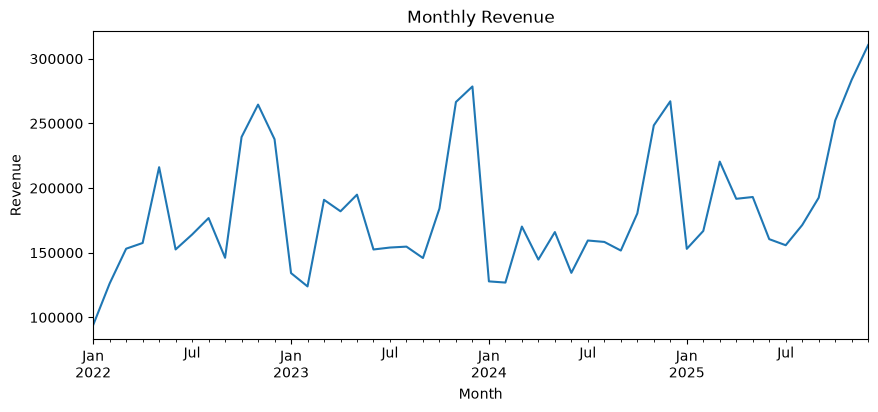

In [35]:
# Plots a line chart of the monthly revenue
monthly = df.groupby("Month")["Revenue"].sum()
monthly.plot(kind="line", figsize=(10, 4), title="Monthly Revenue")
plt.ylabel("Revenue")
plt.show()

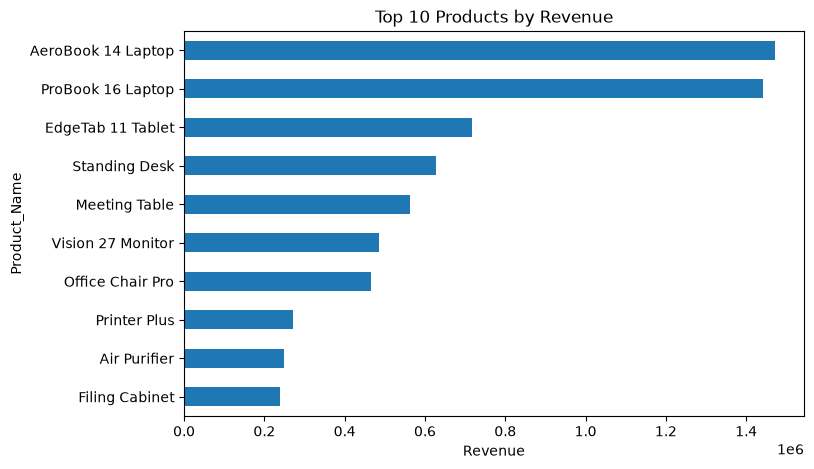

In [34]:
# Plots a horizontal barchart of the products based on revenue
top_products = df.groupby("Product_Name")["Revenue"].sum().nlargest(10)
top_products.sort_values().plot(kind="barh", figsize=(8, 5), title="Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.show()